# 6. Results

Every table and figure of the paper, from the stored readings and judge answers. Runs on a CPU in about five minutes
(two cores). Measures:

* **False approvals**: share of the claims that do not follow (label False or Uncertain) that are approved.
* **Coverage**: share of the claims that follow (label True) that are approved.
* **Referred**: share of all stories sent to review.
* **Retained**: share of stories whose reading sets keep, for the claim and every sentence with a reading, a formula
  equivalent to the expert one.

In [1]:
# Copyright 2026 Javier Marín
# SPDX-License-Identifier: Apache-2.0

from pathlib import Path

REPO = Path.cwd().parent
DATA = REPO / "data"
RUNS = REPO / "runs"      # everything this notebook produces goes here; data/ is never overwritten

import pandas as pd

from logicverifier import analysis as A
from logicverifier import data

sets = data.load_test_sets(DATA / "test_sets")
labels = A.labels_of(sets)
follow = [k for k in labels if labels[k] == "True"]
not_follow = [k for k in labels if labels[k] != "True"]
gpt = A.pooled(A.load_judge(DATA / "judges" / "gpt-6.1-sol.jsonl"))
claude = A.pooled(A.load_judge(DATA / "judges" / "claude-opus-5-5.jsonl"))
shared = [k for k in labels if k in claude]       # FOLIO original and the first 100 stories with new names


def readings(translator):
    return {name: A.load_readings(DATA / "readings" / translator / f"{name}.json") for name in sets}


def evaluate(translator, rules):
    """{rule: {(set, story id): outcome}} over the three sets."""
    by_set = {name: A.evaluate(stories, readings(translator)[name], rules) for name, stories in sets.items()}
    return {rule: A.pooled({name: by_set[name][rule] for name in sets}) for rule in rules}


def approved(outcomes, keys):
    return [(outcomes[k].decision if isinstance(outcomes[k], A.Outcome) else outcomes[k]) == "True" for k in keys]

## Decide every story

Translator v4 under every rule with one to seven readings, and translators v2 and v3 with one and three. Most of the
time goes into the Z3 calls.

In [2]:
Rule = A.Rule
rules_v4 = ([Rule("every", m) for m in range(1, 8)] + [Rule("most_frequent", m) for m in range(2, 8)]
            + [Rule("every", m, "xor") for m in range(1, 8)] + [Rule("every", 1, "args")])
v4 = evaluate("v4", rules_v4)
v2 = evaluate("v2", [Rule("every", 1), Rule("every", 3)])
v3 = evaluate("v3", [Rule("every", 1), Rule("every", 3)])

In every configuration, with one to seven readings and with or without edits, no story that retained its faithful
readings received a false approval (Proposition 1):

In [3]:
sum(o.retained and o.decision == "True" and labels[k] != "True"
    for outcomes in (v4, v2, v3) for by_story in outcomes.values() for k, o in by_story.items())

0

## Table 1. Rules on the same readings of translator v4, and two frontier judges

In [4]:
def row(name, outcomes):
    s, t = A.summarize(outcomes, labels), A.summarize({k: outcomes[k] for k in shared if k in outcomes}, labels)
    return {"Rule": name,
            "Readings per sentence": None if s.mean_size is None else round(s.mean_size, 2),
            "Retained": None if s.retained is None else f"{s.retained_rate:.1%}",
            "False approvals": f"{s.false_approval_rate:.1%} ({s.false_approvals})" if s.stories == len(labels) else "",
            "Coverage": f"{s.coverage:.1%}" if s.stories == len(labels) else "",
            "Referred": f"{s.referred_rate:.1%}" if s.stories == len(labels) else "",
            "Shared: false approvals": f"{t.false_approval_rate:.1%} ({t.false_approvals})",
            "Shared: coverage": f"{t.coverage:.0%}"}


table_1 = [Rule("every", 1), Rule("most_frequent", 3), Rule("most_frequent", 7), Rule("every", 3), Rule("every", 7),
           Rule("every", 3, "xor")]
pd.DataFrame([row(str(r), v4[r]) for r in table_1]
             + [row("gpt-6.1-sol as judge", gpt), row("Claude Opus 5.5 as judge", claude)]).fillna("")

,Rule,Readings per sentence,Retained,False approvals,Coverage,Referred,Shared: false approvals,Shared: coverage
0,One reading (greedy),0.99,47.8%,3.2% (20),72.5%,68.9%,5.6% (10),70%
1,Most frequent of 3,1.0,47.7%,3.0% (19),71.3%,69.3%,5.6% (10),71%
2,Most frequent of 7,1.0,48.9%,3.0% (19),72.5%,68.8%,5.6% (10),73%
3,Every reading of 3,1.19,52.9%,1.4% (9),56.7%,75.8%,2.2% (4),61%
4,Every reading of 7,1.43,56.6%,1.0% (6),48.5%,79.7%,1.7% (3),52%
5,"Every reading of 3, with xor edits",1.31,56.3%,1.3% (8),54.4%,77.4%,2.2% (4),58%
6,gpt-6.1-sol as judge,,,4.4% (28),75.4%,66.3%,3.9% (7),77%
7,Claude Opus 5.5 as judge,,,,,,4.5% (8),91%


### Paired tests between rules (exact McNemar)

In [5]:
def flips(a, b, keys):
    """How many approvals only a gives, only b gives, and the two-sided exact McNemar p-value."""
    x, y = approved(a, keys), approved(b, keys)
    only_a, only_b = sum(p and not q for p, q in zip(x, y)), sum(q and not p for p, q in zip(x, y))
    return f"{only_a} against {only_b}, p = {A.mcnemar(x, y):.2g}"


for m in (3, 7):
    print(f"False approvals, most frequent of {m} against every reading of {m}:", flips(v4[Rule("most_frequent", m)], v4[Rule("every", m)], not_follow))
print("False approvals, one reading against three:", flips(v4[Rule("every", 1)], v4[Rule("every", 3)], not_follow))
print("Correct approvals, one reading against three:", flips(v4[Rule("every", 1)], v4[Rule("every", 3)], follow))
print("Correct approvals, three readings with edits against seven:", flips(v4[Rule("every", 3, "xor")], v4[Rule("every", 7)], follow))
one, three = v4[Rule("every", 1)], v4[Rule("every", 3)]
print("Decisions that changed between PASS and FAIL:", sum({one[k].decision, three[k].decision} == {"True", "False"} for k in labels))
print("Wrong FAIL on true claims sent to review:", sum(labels[k] == "True" and one[k].decision == "False" and three[k].decision == "Uncertain" for k in labels))

False approvals, most frequent of 3 against every reading of 3: 10 against 0, p = 0.002
False approvals, most frequent of 7 against every reading of 7: 13 against 0, p = 0.00024
False approvals, one reading against three: 11 against 0, p = 0.00098
Correct approvals, one reading against three: 28 against 1, p = 1.1e-07
Correct approvals, three readings with edits against seven: 14 against 4, p = 0.031
Decisions that changed between PASS and FAIL: 0
Wrong FAIL on true claims sent to review: 3


## Figure 1

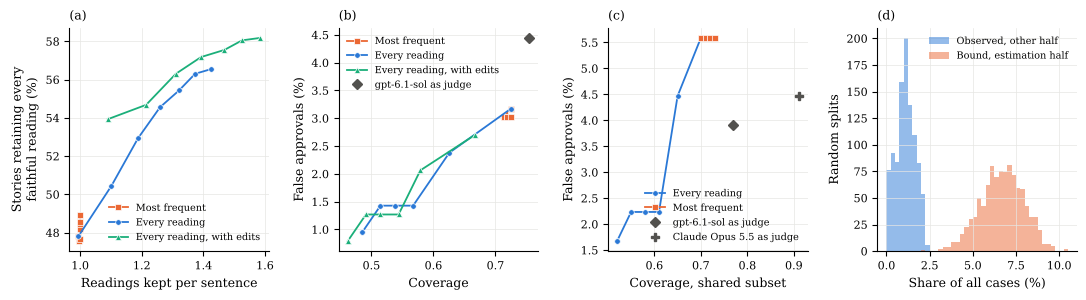

In [6]:
curves = {"Most frequent": [A.summarize(v4[Rule("every", 1)], labels)] + [A.summarize(v4[Rule("most_frequent", m)], labels) for m in range(2, 8)],
          "Every reading": [A.summarize(v4[Rule("every", m)], labels) for m in range(1, 8)],
          "Every reading, with edits": [A.summarize(v4[Rule("every", m, "xor")], labels) for m in range(1, 8)]}
shared_labels = {k: labels[k] for k in shared}
curves_shared = {name: [A.summarize(v4[Rule("every", m)], shared_labels) for m in range(1, 8)] for name in ["Every reading"]}
curves_shared["Most frequent"] = [A.summarize(v4[Rule("every", 1)], shared_labels)] + [A.summarize(v4[Rule("most_frequent", m)], shared_labels) for m in range(2, 8)]
(REPO / "figures").mkdir(exist_ok=True)
splits = A.validate_estimate(three, labels, {k: sets[k[0]][k[1]]["source_idx"] for k in labels}, splits=1000, seed=0)
figure = A.plot_main_figure(curves, {"gpt-6.1-sol": A.summarize(gpt, labels)}, curves_shared,
                            {"gpt-6.1-sol": A.summarize(gpt, shared_labels), "Claude Opus 5.5": A.summarize(claude, shared_labels)},
                            splits, path=REPO / "figures" / "fig_main.pdf")

## Table 2. Comparison with frontier judges

In [7]:
def paired(name, outcomes, judge, keys_follow, keys_not_follow):
    cov_v, cov_j = approved(outcomes, keys_follow), approved(judge, keys_follow)
    fa_v, fa_j = approved(outcomes, keys_not_follow), approved(judge, keys_not_follow)
    diff, low, high = A.bootstrap_difference(fa_v, fa_j)
    star = lambda a, b: "*" if A.mcnemar(a, b) < 0.05 else ""
    return {"Verifier": name,
            "Coverage, verifier": f"{sum(cov_v) / len(cov_v):.1%}{star(cov_v, cov_j)}", "Coverage, judge": f"{sum(cov_j) / len(cov_j):.1%}",
            "False approvals, verifier": f"{sum(fa_v) / len(fa_v):.1%} ({sum(fa_v)}){star(fa_v, fa_j)}",
            "False approvals, judge": f"{sum(fa_j) / len(fa_j):.1%} ({sum(fa_j)})",
            "Difference [95% CI]": f"{diff:.1f} [{low:.1f}, {high:.1f}]"}


follow_shared = [k for k in follow if k in claude]
not_follow_shared = [k for k in not_follow if k in claude]
pd.DataFrame([
    paired("v2, 1 reading, against gpt-6.1-sol", v2[Rule("every", 1)], gpt, follow, not_follow),
    paired("v4, 1 reading, against gpt-6.1-sol", v4[Rule("every", 1)], gpt, follow, not_follow),
    paired("v2, 3 readings, against gpt-6.1-sol", v2[Rule("every", 3)], gpt, follow, not_follow),
    paired("v4, 3 readings, against gpt-6.1-sol", v4[Rule("every", 3)], gpt, follow, not_follow),
    paired("v2, 3 readings, against Claude Opus 5.5 (shared)", v2[Rule("every", 3)], claude, follow_shared, not_follow_shared),
    paired("v4, 3 readings, against Claude Opus 5.5 (shared)", v4[Rule("every", 3)], claude, follow_shared, not_follow_shared),
    paired("v4, 3 readings, against gpt-6.1-sol (shared)", v4[Rule("every", 3)], gpt, follow_shared, not_follow_shared),
])

,Verifier,"Coverage, verifier","Coverage, judge","False approvals, verifier","False approvals, judge",Difference [95% CI]
0,"v2, 1 reading, against gpt-6.1-sol",76.0%,75.4%,4.0% (25),4.4% (28),"-0.5 [-2.1, 1.1]"
1,"v4, 1 reading, against gpt-6.1-sol",72.5%,75.4%,3.2% (20),4.4% (28),"-1.3 [-2.9, 0.2]"
2,"v2, 3 readings, against gpt-6.1-sol",63.7%*,75.4%,1.9% (12)*,4.4% (28),"-2.5 [-4.1, -1.1]"
3,"v4, 3 readings, against gpt-6.1-sol",56.7%*,75.4%,1.4% (9)*,4.4% (28),"-3.0 [-4.6, -1.6]"
4,"v2, 3 readings, against Claude Opus 5.5 (shared)",64.0%*,91.0%,3.4% (6),4.5% (8),"-1.1 [-3.9, 1.7]"
5,"v4, 3 readings, against Claude Opus 5.5 (shared)",61.0%*,91.0%,2.2% (4),4.5% (8),"-2.2 [-5.6, 0.6]"
6,"v4, 3 readings, against gpt-6.1-sol (shared)",61.0%*,77.0%,2.2% (4),3.9% (7),"-1.7 [-4.5, 1.1]"


Accuracy of Claude Opus 5.5 on the shared subset:

In [8]:
A.summarize(claude, labels).accuracy

0.899641577060932

## Table 3. When a premise is missing

Counterfactual stories whose original claim was True: in 159 the claim no longer follows after one premise is
removed, in 47 it still does.

In [9]:
counterfactual = sets["folio_counterfactual"]
gone = [("folio_counterfactual", i) for i, s in counterfactual.items() if s["kind"] == "drop_changed" and s["orig_label"] == "True"]
still = [("folio_counterfactual", i) for i, s in counterfactual.items() if s["kind"] == "drop_control" and s["orig_label"] == "True"]


def missing_row(name, outcomes):
    a, b = approved(outcomes, gone), approved(outcomes, still)
    star = lambda x, y: "*" if outcomes is not gpt and A.mcnemar(x, y) < 0.05 else ""
    return {"System": name, f"Claim no longer follows ({len(gone)})": f"{sum(a)} ({sum(a) / len(a):.1%}){star(a, approved(gpt, gone))}",
            f"Claim still follows ({len(still)})": f"{sum(b)} ({sum(b) / len(b):.0%}){star(b, approved(gpt, still))}"}


pd.DataFrame([missing_row("gpt-6.1-sol as judge", gpt)] + [missing_row(str(r), v4[r]) for r in
              (Rule("every", 1), Rule("most_frequent", 3), Rule("every", 3), Rule("every", 7))])

,System,Claim no longer follows (159),Claim still follows (47)
0,gpt-6.1-sol as judge,11 (6.9%),36 (77%)
1,One reading (greedy),4 (2.5%)*,36 (77%)
2,Most frequent of 3,4 (2.5%)*,33 (70%)
3,Every reading of 3,2 (1.3%)*,19 (40%)*
4,Every reading of 7,1 (0.6%)*,16 (34%)*


In [10]:
judged_true = [k for k in gone if gpt[k] == "True"]
originals = {("folio_original", f"o{counterfactual[k[1]]['source_idx']}") for k in judged_true}
print("The judge approved the original version of every one:", all(gpt[k] == "True" for k in originals))
print("The verifier's approvals with three readings are cases the judge also approved:",
      all(gpt[k] == "True" for k in gone if three[k].decision == "True"))

The judge approved the original version of every one: True
The verifier's approvals with three readings are cases the judge also approved: True


## Bounding the rate of false approvals

With three readings: the share of approvals times the exact upper bound on the share of approvals that lost a
faithful reading. Here the expert formulas play the person who formalizes the sampled sentences.

In [11]:
bound, lost, n_approved = A.estimate_bound(three.values())
print(f"{n_approved} approvals of {len(three)} stories ({n_approved / len(three):.0%}), {lost} lost a faithful reading")
print(f"Bound on the rate of false approvals: {bound:.1%}. Outer bound P(L): {A.outer_bound(three.values()):.0%}")

106 approvals of 801 stories (13%), 41 lost a faithful reading
Bound on the rate of false approvals: 6.2%. Outer bound P(L): 47%


In [12]:
held = sum(b >= o for b, o in splits)
print(f"Random splits that keep each FOLIO story and its variants on one side: {len(splits)}")
print(f"The bound held in {held}. Mean bound {sum(b for b, _ in splits) / len(splits):.1%} of all cases, "
      f"mean observed rate {sum(o for _, o in splits) / len(splits):.1%}")

Random splits that keep each FOLIO story and its variants on one side: 1000
The bound held in 1000. Mean bound 6.7% of all cases, mean observed rate 1.1%


## Appendix B. Results by set

In [13]:
def by_set(name, outcomes):
    out = {"System": name}
    for set_name, title in data.SETS.items():
        part = {k: o for k, o in outcomes.items() if k[0] == set_name}
        if part:
            s = A.summarize(part, labels)
            out[f"{title}: accuracy"] = f"{s.accuracy:.3f}"
            out[f"{title}: coverage"] = f"{s.coverage:.3f}"
            out[f"{title}: false approvals"] = f"{s.false_approval_rate:.1%} ({s.false_approvals})"
    return out


pd.DataFrame([by_set("Translator v2, 1 reading", v2[Rule("every", 1)]), by_set("Translator v2, 3 readings", v2[Rule("every", 3)]),
              by_set("Translator v4, 1 reading", v4[Rule("every", 1)]), by_set("Translator v4, 3 readings", v4[Rule("every", 3)]),
              by_set("gpt-6.1-sol as judge", gpt), by_set("Claude Opus 5.5 as judge", claude)]).T

,0,1,2,3,4,5
System,"Translator v2, 1 reading","Translator v2, 3 readings","Translator v4, 1 reading","Translator v4, 3 readings",gpt-6.1-sol as judge,Claude Opus 5.5 as judge
FOLIO original: accuracy,0.855,0.821,0.793,0.749,0.821,0.905
FOLIO original: coverage,0.806,0.726,0.694,0.629,0.790,0.919
FOLIO original: false approvals,5.1% (6),2.6% (3),5.1% (6),2.6% (3),4.3% (5),4.3% (5)
FOLIO with new names: accuracy,0.810,0.698,0.782,0.726,0.782,0.890
FOLIO with new names: coverage,0.726,0.532,0.726,0.629,0.710,0.895
FOLIO with new names: false approvals,3.4% (4),3.4% (4),4.3% (5),1.7% (2),4.3% (5),4.8% (3)
FOLIO counterfactual: accuracy,0.907,0.919,0.926,0.896,0.889,NaN
FOLIO counterfactual: coverage,0.745,0.660,0.766,0.404,0.766,NaN
FOLIO counterfactual: false approvals,3.8% (15),1.3% (5),2.3% (9),1.0% (4),4.5% (18),NaN


In [14]:
for name, outcomes in (("v2", v2[Rule("every", 3)]), ("v4", three)):
    kept = {s: sum(o.retained for k, o in outcomes.items() if k[0] == s) for s in data.SETS}
    print(f"{name}, three readings, stories retained:", kept)

v2, three readings, stories retained: {'folio_original': 88, 'folio_new_names': 74, 'folio_counterfactual': 208}
v4, three readings, stories retained: {'folio_original': 96, 'folio_new_names': 92, 'folio_counterfactual': 236}


## Appendix C. Translator v3

In [15]:
pd.DataFrame([by_set("Translator v3, 1 reading", v3[Rule("every", 1)]), by_set("Translator v3, 3 readings", v3[Rule("every", 3)])]).T

,0,1
System,"Translator v3, 1 reading","Translator v3, 3 readings"
FOLIO original: accuracy,0.821,0.793
FOLIO original: coverage,0.774,0.694
FOLIO original: false approvals,4.3% (5),4.3% (5)
FOLIO with new names: accuracy,0.804,0.749
FOLIO with new names: coverage,0.742,0.613
FOLIO with new names: false approvals,4.3% (5),4.3% (5)
FOLIO counterfactual: accuracy,0.919,0.923
FOLIO counterfactual: coverage,0.745,0.681
FOLIO counterfactual: false approvals,3.5% (14),1.3% (5)


Before the vocabulary was corrected, translator v3 retained the faithful readings of more stories than v2 with one
reading. These are the readings and sets of that earlier run:

In [16]:
before = DATA / "before_vocabulary_fix"
old_sets = data.load_test_sets(before / "test_sets")
for name, stories in old_sets.items():
    kept = []
    for translator in ("v2", "v3"):
        outcomes = A.evaluate(stories, A.load_readings(before / "readings" / translator / f"{name}.json"), [Rule("every", 1)])
        kept.append(sum(o.retained for o in outcomes[Rule("every", 1)].values()))
    print(f"{data.SETS[name]:24s} v2 {kept[0]:3d}  v3 {kept[1]:3d}  ({kept[1] / kept[0] - 1:+.0%})")

FOLIO original           v2  70  v3  82  (+17%)


FOLIO with new names     v2  60  v3  79  (+32%)


FOLIO counterfactual     v2 170  v3 205  (+21%)


### Controls outside FOLIO

In [17]:
import json

controls = {t: json.loads((DATA / "controls" / f"{t}.json").read_text())["metrics"] for t in ("v2", "v3", "v4")}
pd.DataFrame({t: {"DGT, valid formulas": f"{m['dgt']['parse_rate']:.1%}",
                  "DGT, negations kept from the English formula": f"{m['dgt']['vs_english']['same_negations']:.1%}",
                  "DGT, numbers kept from the English formula": f"{m['dgt']['vs_english']['same_numbers']:.1%}",
                  "Common sense, accuracy": f"{m['wikidata']['accuracy']:.1%}",
                  "FOLIO without a vocabulary, accuracy": f"{m['folio']['accuracy']:.1%}"} for t, m in controls.items()})

,v2,v3,v4
"DGT, valid formulas",96.2%,95.1%,97.1%
"DGT, negations kept from the English formula",84.3%,87.5%,86.0%
"DGT, numbers kept from the English formula",73.8%,70.8%,71.3%
"Common sense, accuracy",92.6%,92.4%,92.3%
"FOLIO without a vocabulary, accuracy",71.6%,63.2%,60.8%


## Appendix E. Directed edits

In [18]:
for rule in (Rule("every", 1, "xor"), Rule("every", 2), Rule("every", 3, "xor"), Rule("every", 7)):
    s = A.summarize(v4[rule], labels)
    print(f"{str(rule):38s} readings per sentence {s.mean_size:.2f}  retained {s.retained:3d}  correct approvals {s.approved_follow:3d}  false approvals {s.false_approvals}")
original = [k for k in labels if k[0] == "folio_original"]
for rule in (Rule("every", 1), Rule("every", 1, "args")):
    s = A.summarize({k: v4[rule][k] for k in original}, labels)
    print(f"FOLIO original, {str(rule):28s} retained {s.retained}  coverage {s.coverage:.0%}")

One reading (greedy), with xor edits   readings per sentence 1.09  retained 432  correct approvals 114  false approvals 17
Every reading of 2                     readings per sentence 1.10  retained 404  correct approvals 107  false approvals 15
Every reading of 3, with xor edits     readings per sentence 1.31  retained 451  correct approvals  93  false approvals 8
Every reading of 7                     readings per sentence 1.43  retained 453  correct approvals  83  false approvals 6
FOLIO original, One reading (greedy)         retained 83  coverage 69%
FOLIO original, One reading (greedy), with args edits retained 83  coverage 50%
